# GNN: Rank Loss Models

Trains three GNN variants (Correlation, Sector, Granger) using a pairwise BPR rank loss
instead of MSE. The rank loss directly optimizes cross-sectional ordering of predicted RV,
which is what the inverse-vol and long-short portfolios reward.

These models are **separate** from the MSE-trained models in `04_gnn_models.ipynb`.
Checkpoints use `_rankloss` suffixes and test predictions are saved to separate parquet files.
Both model families can be evaluated side-by-side in `05_evaluate.ipynb`.

Architecture is identical to the MSE models:
- **Correlation**: GNNModelV2 with hparam-tuned config (if available), else GNNModel
- **Sector**: GNNModel
- **Granger**: GNNModel

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path('..').resolve()))

import json
import numpy as np
import pandas as pd
import torch
from pathlib import Path

import config
from src.models import GNNModel, compute_har_features
from src.train import (
    set_seeds,
    compute_rank_loss,
    train_gnn_corr_rankloss,
    train_gnn_sector_rankloss,
    train_gnn_granger_rankloss,
)
from src.graphs import (
    build_all_sector_graphs,
    build_granger_graph,
    precompute_corr_graphs,
    load_corr_graphs,
)
from src.train import predict_gnn_split

In [2]:
# Load all data
target    = pd.read_parquet(Path(config.DATA_FEATURES_DIR) / 'target.parquet')
splits    = pd.read_parquet(Path(config.DATA_FEATURES_DIR) / 'splits.parquet')
tickers   = target.columns.tolist()

meta          = json.load(open(Path(config.DATA_FEATURES_DIR) / 'features_meta.json'))
feature_names = meta['feature_names']
feat_df       = pd.read_parquet(Path(config.DATA_FEATURES_DIR) / 'features.parquet')
feat_df['week'] = pd.to_datetime(feat_df['week'])
feat_df = feat_df[feat_df['week'].isin(target.index)].copy()
ticker_order    = {t: i for i, t in enumerate(tickers)}
feat_df['_ord'] = feat_df['ticker'].map(ticker_order)
feat_df = feat_df.sort_values(['week', '_ord']).drop(columns='_ord')

n_weeks  = target.shape[0]
n_stocks = target.shape[1]
n_feats  = len(feature_names)

features_3d = feat_df[feature_names].values.reshape(n_weeks, n_stocks, n_feats)
target_arr  = target.values

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

assert features_3d.shape == (n_weeks, n_stocks, n_feats)
assert target_arr.shape  == (n_weeks, n_stocks)
print(f'features_3d: {features_3d.shape}  target_arr: {target_arr.shape}')
print(f'tickers: {len(tickers)}  n_feats: {n_feats}  device: {device}')

features_3d: (572, 460, 10)  target_arr: (572, 460)
tickers: 460  n_feats: 10  device: cpu


In [5]:
log_returns    = pd.read_parquet(Path(config.DATA_RAW_DIR) / 'log_returns.parquet')
sector_history = json.load(open(Path(config.DATA_RAW_DIR) / 'sector_history.json'))
granger_df     = pd.read_parquet(Path(config.DATA_GRAPHS_DIR) / 'granger_edges.parquet')

granger_edge_index = torch.tensor(
    granger_df[['src', 'dst']].values.T, dtype=torch.long
)

# Pre-build sector graphs for all years
sector_graphs_dict = build_all_sector_graphs(
    tickers=tickers,
    sector_history=sector_history,
    years=range(2015, 2026),
)

# Correlation graphs — already precomputed by 04_gnn_models.ipynb, skips if exists
precompute_corr_graphs(log_returns=log_returns, splits=splits)

ablation_path = Path(config.DATA_RESULTS_DIR) / 'corr_threshold_ablation.json'

if ablation_path.exists():
    ablation_data = json.load(open(ablation_path))
else:
    # Reconstruct the selection from each threshold's saved validation results.
    val_loss_paths = sorted(
        Path(config.DATA_RESULTS_DIR).glob('gnn_corr_th*_val_loss.json')
    )
    candidates = []

    for path in val_loss_paths:
        threshold_code = path.stem.split('_th')[-1].split('_')[0]
        threshold = int(threshold_code) / 10
        loss_data = json.load(open(path))
        best_val_mse = loss_data.get(
            'best_val_loss',
            min(loss_data['val_loss']) if loss_data.get('val_loss') else None,
        )
        if best_val_mse is not None:
            candidates.append((threshold, float(best_val_mse)))

    if not candidates:
        fallback_theta = getattr(config, 'CORR_THRESHOLD', None)
        if fallback_theta is None:
            raise FileNotFoundError(
            f'No correlation-threshold validation artifacts were found in '
            f'{config.DATA_RESULTS_DIR}, and config.CORR_THRESHOLD is not set. '
            'Run the correlation-threshold ablation in 04_gnn_models.ipynb.'
            )

        candidates.append((float(fallback_theta), np.nan))
        print(
            f'Warning: no ablation results found; using configured '
            f'CORR_THRESHOLD={fallback_theta} (not validation-selected).'
        )

    best_theta, best_val_mse = min(candidates, key=lambda item: item[1])
    ablation_data = {
        'best_threshold': best_theta,
        'best_val_mse': best_val_mse,
    }
    print(f'Reconstructed threshold selection from validation artifacts: θ={best_theta}')
best_theta    = ablation_data['best_threshold']

# Load train+val corr graphs for the winning threshold
corr_graphs = {
    **load_corr_graphs(best_theta, 'train'),
    **load_corr_graphs(best_theta, 'val'),
}

print(f'Granger edges:   {granger_edge_index.shape[1]:,}')
print(f'Corr threshold:  θ={best_theta}')
print(f'Corr graphs loaded: {len(corr_graphs)} weeks')

Saved 267490 total edges across 11 years to /Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/data/graphs/sector_edges_by_year.parquet
  train/t0p3: already exists, skipping
  train/t0p5: already exists, skipping
  train/t0p7: already exists, skipping
  val/t0p3: already exists, skipping
  val/t0p5: already exists, skipping
  val/t0p7: already exists, skipping
  test/t0p3: already exists, skipping
  test/t0p5: already exists, skipping
  test/t0p7: already exists, skipping
precompute_corr_graphs: done.
Reconstructed threshold selection from validation artifacts: θ=0.3
Granger edges:   0
Corr threshold:  θ=0.3
Corr graphs loaded: 469 weeks


## Rank Loss Sanity Check

Verify that `compute_rank_loss` returns a differentiable scalar on one sample step.
The loss should be positive and have a grad_fn (so gradients flow through it).

In [6]:
sample_pos  = 200
sample_week = target.index[sample_pos]

set_seeds()
_test_model = GNNModel(in_channels=n_feats).to(device)
x_t = torch.tensor(features_3d[sample_pos], dtype=torch.float32).to(device)
y_t = torch.tensor(target_arr[sample_pos],   dtype=torch.float32).to(device)

# Use a static sector graph for this check (no dynamic recomputation)
ei_t  = sector_graphs_dict[sample_week.year].to(device)
preds = _test_model(x_t, ei_t)

rank_loss_val = compute_rank_loss(preds, y_t)
mse_loss_val  = torch.nn.functional.mse_loss(
    preds[~y_t.isnan()], y_t[~y_t.isnan()]
)

print(f'Week: {sample_week.date()}')
print(f'Rank loss : {rank_loss_val.item():.6f}  grad_fn={rank_loss_val.grad_fn}')
print(f'MSE loss  : {mse_loss_val.item():.6f}  grad_fn={mse_loss_val.grad_fn}')

assert rank_loss_val.grad_fn is not None, 'Rank loss has no grad_fn — cannot backprop'
assert mse_loss_val.grad_fn  is not None, 'MSE loss has no grad_fn'

# Verify gradients flow through rank loss
rank_loss_val.backward()
max_grad = max(p.grad.abs().max().item() for p in _test_model.parameters() if p.grad is not None)
print(f'Max gradient magnitude after rank loss backward: {max_grad:.6f}')
assert max_grad > 0, 'Zero gradients — rank loss is not training the model'
print('Sanity check passed.')
del _test_model

Week: 2018-11-05
Rank loss : 0.692623  grad_fn=<MeanBackward0 object at 0x141f16410>
MSE loss  : 0.260957  grad_fn=<MseLossBackward0 object at 0x141f15ab0>
Max gradient magnitude after rank loss backward: 0.096573
Sanity check passed.


/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/src/models.py:289: UserWarning: GNNModel.forward: input features contain NaN values. Imputing with 0 (z-score mean). Expected during warm-up weeks.
  warnings.warn(


## GNN-Correlation — Rank Loss

Trains using the best correlation threshold (θ=ablation winner) and the hparam-tuned
GNNModelV2 architecture. Skips training if the checkpoint already exists.

In [7]:
_ckpt_path = Path(config.CHECKPOINTS_DIR) / 'gnn_corr_rankloss_best.pt'

if _ckpt_path.exists():
    print('gnn_corr_rankloss_best.pt found — skipping training.')
    _loss_data = json.load(open(Path(config.DATA_RESULTS_DIR) / 'gnn_corr_rankloss_val_loss.json'))
    corr_rl_val_loss = _loss_data['val_loss']
    print(f'Best val rank loss: {_loss_data["best_val_loss"]:.6f}')
else:
    _, corr_rl_val_loss = train_gnn_corr_rankloss(
        features=features_3d,
        target=target_arr,
        week_index=target.index,
        corr_graphs=corr_graphs,
        splits=splits,
        device=device,
    )
    print(f'Training complete. Checkpoint: gnn_corr_rankloss_best.pt')

/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/.venv/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:60: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch   1  train=0.616623  val=0.623130
Epoch   2  train=0.612824  val=0.621722
Epoch   3  train=0.611532  val=0.621883
Epoch   4  train=0.611130  val=0.622068
Epoch   5  train=0.610559  val=0.620923
Epoch   6  train=0.610285  val=0.621379
Epoch   7  train=0.609745  val=0.620577
Epoch   8  train=0.608946  val=0.621049
Epoch   9  train=0.608868  val=0.621408
Epoch  10  train=0.608823  val=0.621318
Epoch  11  train=0.608767  val=0.618922
Epoch  12  train=0.608219  val=0.619552
Epoch  13  train=0.608513  val=0.619948
Epoch  14  train=0.607911  val=0.620500
Epoch  15  train=0.607310  val=0.619137
Epoch  16  train=0.607676  val=0.620580
Epoch  17  train=0.607378  val=0.619566
Epoch  18  train=0.605809  val=0.619070
Epoch  19  train=0.605560  val=0.619556
Epoch  20  train=0.605157  val=0.619249
Epoch  21  train=0.605038  val=0.619022
Early stop at epoch 21 (no improvement for 10 epochs)
Training complete. Checkpoint: gnn_corr_rankloss_best.pt


## GNN-Sector — Rank Loss

In [8]:
_ckpt_path = Path(config.CHECKPOINTS_DIR) / 'gnn_sector_rankloss_best.pt'

if _ckpt_path.exists():
    print('gnn_sector_rankloss_best.pt found — skipping training.')
    _loss_data = json.load(open(Path(config.DATA_RESULTS_DIR) / 'gnn_sector_rankloss_val_loss.json'))
    sector_rl_val_loss = _loss_data['val_loss']
    print(f'Best val rank loss: {_loss_data["best_val_loss"]:.6f}')
else:
    _, sector_rl_val_loss = train_gnn_sector_rankloss(
        features=features_3d,
        target=target_arr,
        week_index=target.index,
        sector_graphs=sector_graphs_dict,
        splits=splits,
        device=device,
    )
    print(f'Training complete. Checkpoint: gnn_sector_rankloss_best.pt')

Epoch   1  train=0.618060  val=0.626132
Epoch   2  train=0.613897  val=0.624371
Epoch   3  train=0.612566  val=0.624634
Epoch   4  train=0.612157  val=0.624939
Epoch   5  train=0.611674  val=0.623642
Epoch   6  train=0.611382  val=0.623981
Epoch   7  train=0.610696  val=0.622805
Epoch   8  train=0.609825  val=0.622861
Epoch   9  train=0.610089  val=0.622626
Epoch  10  train=0.609544  val=0.622878
Epoch  11  train=0.609595  val=0.620802
Epoch  12  train=0.609061  val=0.622013
Epoch  13  train=0.609304  val=0.621967
Epoch  14  train=0.608750  val=0.622647
Epoch  15  train=0.608311  val=0.621406
Epoch  16  train=0.608438  val=0.622271
Epoch  17  train=0.608118  val=0.621577
Epoch  18  train=0.606826  val=0.621380
Epoch  19  train=0.606268  val=0.621532
Epoch  20  train=0.605874  val=0.621054
Epoch  21  train=0.605707  val=0.620836
Early stop at epoch 21 (no improvement for 10 epochs)
Training complete. Checkpoint: gnn_sector_rankloss_best.pt


## GNN-Granger — Rank Loss

In [34]:
from pathlib import Path

_ckpt_path = Path(config.CHECKPOINTS_DIR) / 'gnn_granger_rankloss_best.pt'

if _ckpt_path.exists():
    print('gnn_granger_rankloss_best.pt found — skipping training.')
    loss_path = Path(config.DATA_RESULTS_DIR) / 'gnn_granger_rankloss_val_loss.json'
    with loss_path.open(encoding='utf-8') as fh:
        _loss_data = json.load(fh)
    granger_rl_val_loss = _loss_data['val_loss']
    print(f"Best val rank loss: {_loss_data['best_val_loss']:.6f}")
else:
    if granger_edge_index.ndim != 2 or granger_edge_index.shape[0] != 2:
        raise ValueError(
            f'Expected granger_edge_index shape (2, num_edges); '
            f'got {tuple(granger_edge_index.shape)}.'
        )

    if granger_edge_index.shape[1] == 0:
        pvalues_path = Path(config.DATA_GRAPHS_DIR) / 'granger_pvalues.parquet'
        if not pvalues_path.is_file():
            raise FileNotFoundError(
                f'{pvalues_path} is missing; rerun Granger p-value computation '
                'in 03_graphs.ipynb.'
            )

        # Reuse the project's canonical matrix orientation and correction logic.
        # build_granger_graph maps matrix[row=target, col=cause] to cause -> target.
        granger_edge_index, correction_used = build_granger_graph(
            tickers=tickers,
            correction=config.GRANGER_CORRECTION,
        )
        if granger_edge_index.shape[1] == 0:
            raise RuntimeError(
                f'No Granger edges survived {correction_used} correction. '
                f'The p-value artifact at {pvalues_path} may contain placeholder '
                'values (for example, all 1.0). Recompute the raw Granger '
                'p-values in 03_graphs.ipynb, then rerun this cell.'
            )
        print(
            f'Rebuilt Granger graph with {granger_edge_index.shape[1]:,} '
            f'{correction_used}-significant edges.'
        )

    _, granger_rl_val_loss = train_gnn_granger_rankloss(
        features=features_3d,
        target=target_arr,
        week_index=target.index,
        granger_edge_index=granger_edge_index,
        splits=splits,
        device=device,
    )
    print('Training complete. Checkpoint: gnn_granger_rankloss_best.pt')


gnn_granger_rankloss_best.pt found — skipping training.
Best val rank loss: 0.619876


## Test Predictions

Generate test-set predictions for all three rank-loss models and save to parquet.
Saved as `test_preds_gnn_{variant}_rankloss.parquet` — separate from the MSE model parquets.

In [35]:
from src.evaluate import _load_gnn_model
from src.models import GNNModelV2

results_dir = Path(config.DATA_RESULTS_DIR)
ckpt_dir    = Path(config.CHECKPOINTS_DIR)
test_corr_graphs = load_corr_graphs(best_theta, 'test')

# GNN-Correlation rank loss — use GNNModelV2 if hparam config exists
hparam_json = results_dir / 'gnn_hparam_search_results.json'
if hparam_json.exists():
    hparam_cfg = json.load(open(hparam_json))['best_config']
    corr_rl_model = GNNModelV2(
        in_channels=n_feats,
        hidden_dim=int(hparam_cfg['hidden_dim']),
        dropout=float(hparam_cfg['dropout']),
        num_layers=int(hparam_cfg['num_layers']),
        batch_norm=bool(hparam_cfg['batch_norm']),
    ).to(device)
    corr_rl_model.load_state_dict(
        torch.load(ckpt_dir / 'gnn_corr_rankloss_best.pt', map_location=device, weights_only=True)
    )
else:
    corr_rl_model = _load_gnn_model(ckpt_dir / 'gnn_corr_rankloss_best.pt', n_feats, device)

sector_rl_model  = _load_gnn_model(ckpt_dir / 'gnn_sector_rankloss_best.pt',  n_feats, device)
granger_rl_model = _load_gnn_model(ckpt_dir / 'gnn_granger_rankloss_best.pt', n_feats, device)

model_configs = [
    ('gnn_corr_rankloss',    corr_rl_model,    lambda w, g=test_corr_graphs: g.get(w, torch.zeros(2, 0, dtype=torch.long))),
    ('gnn_sector_rankloss',  sector_rl_model,  lambda w: sector_graphs_dict[w.year]),
    ('gnn_granger_rankloss', granger_rl_model, lambda w: granger_edge_index),
]

for key, model, edge_fn in model_configs:
    preds_df = predict_gnn_split(
        model=model,
        features=features_3d,
        week_index=target.index,
        edge_index_fn=edge_fn,
        splits=splits,
        tickers=tickers,
        device=device,
        split_name='test',
    )
    out_path = results_dir / f'test_preds_{key}.parquet'
    preds_df.to_parquet(out_path)
    print(f'{key}: shape={preds_df.shape}  saved -> {out_path.name}')

/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/src/models.py:289: UserWarning: GNNModel.forward: input features contain NaN values. Imputing with 0 (z-score mean). Expected during warm-up weeks.
  warnings.warn(


gnn_corr_rankloss: shape=(103, 460)  saved -> test_preds_gnn_corr_rankloss.parquet


/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/src/models.py:289: UserWarning: GNNModel.forward: input features contain NaN values. Imputing with 0 (z-score mean). Expected during warm-up weeks.
  warnings.warn(


gnn_sector_rankloss: shape=(103, 460)  saved -> test_preds_gnn_sector_rankloss.parquet
gnn_granger_rankloss: shape=(103, 460)  saved -> test_preds_gnn_granger_rankloss.parquet


/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/src/models.py:289: UserWarning: GNNModel.forward: input features contain NaN values. Imputing with 0 (z-score mean). Expected during warm-up weeks.
  warnings.warn(


## Experiment registry reference

Current training and evaluation artifacts should be registered before downstream comparison.

In [36]:
# REGISTRY_REFERENCE_CELL
from pathlib import Path
import pandas as pd
from IPython.display import display

registry_path = Path('../data/results/experiment_registry.csv')
registry = pd.read_csv(registry_path)
display(registry[['experiment_id', 'model_name', 'feature_version', 'graph_version', 'checkpoint_path']])
print(f'Registry path: {registry_path.as_posix()}')


,experiment_id,model_name,feature_version,graph_version,checkpoint_path
0,baseline_har_per_stock,HAR per-stock,har_realized_volatility_lags_v1,none,NaN
1,baseline_har_pooled,HAR pooled,har_realized_volatility_lags_v1,none,NaN
2,baseline_lstm,LSTM,stock_features_v1,none,data/results/checkpoints/lstm_best.pt
3,baseline_gnn_correlation,GNN-Correlation,stock_features_v1,correlation_threshold_0.3_lookback_252,NaN
4,baseline_gnn_sector,GNN-Sector,stock_features_v1,sector_canonical_gics_labels_v1,NaN
5,baseline_gnn_granger,GNN-Granger,stock_features_v1,granger_lag_5_bonferroni,NaN
6,baseline_gnn_ensemble,GNN-Ensemble,stock_features_v1,correlation+sector+granger_v1,NaN
7,rankloss_gnn_correlation,Rank-loss GNN-Correlation,stock_features_v1,correlation_threshold_0.3_lookback_252,NaN
8,rankloss_gnn_sector,Rank-loss GNN-Sector,stock_features_v1,sector_canonical_gics_labels_v1,NaN
9,rankloss_gnn_granger,Rank-loss GNN-Granger,stock_features_v1,granger_lag_5_bonferroni,NaN


Registry path: ../data/results/experiment_registry.csv


## Val MSE Comparison: MSE Loss vs Rank Loss

Compute val-set MSE for the rank-loss models so they can be compared to the MSE-trained
models on the same scale. Val rank loss values are not directly comparable to MSE.

In [37]:
from src.evaluate import compute_metrics

val_weeks  = sorted(splits.loc[splits['split'] == 'val', 'week'])
target_df  = pd.DataFrame(target_arr, index=target.index, columns=tickers)
target_val = target_df.loc[target_df.index.isin(val_weeks)]

val_corr_graphs = load_corr_graphs(best_theta, 'val')

rl_model_configs = [
    ('GNN-Correlation (rank loss)', corr_rl_model,    lambda w, g=val_corr_graphs: g.get(w, torch.zeros(2, 0, dtype=torch.long))),
    ('GNN-Sector (rank loss)',      sector_rl_model,  lambda w: sector_graphs_dict[w.year]),
    ('GNN-Granger (rank loss)',     granger_rl_model, lambda w: granger_edge_index),
]

rl_val_mse: dict[str, float] = {}
for label, model, edge_fn in rl_model_configs:
    preds_val = predict_gnn_split(
        model=model,
        features=features_3d,
        week_index=target.index,
        edge_index_fn=edge_fn,
        splits=splits,
        tickers=tickers,
        device=device,
        split_name='val',
    ).reindex(target_val.index)
    m = compute_metrics(target_val.values, preds_val.values)
    rl_val_mse[label] = m['mse']

# Load only MSE validation metrics that were actually produced.
mse_val_mse = {
    f'GNN-Correlation (θ={best_theta}, MSE)': ablation_data['best_val_mse'],
}
for graph_name in ('sector', 'granger'):
    loss_path = results_dir / f'gnn_{graph_name}_val_loss.json'
    if loss_path.is_file():
        with loss_path.open() as f:
            mse_val_mse[f'GNN-{graph_name.title()} (MSE)'] = json.load(f)['best_val_loss']
    else:
        print(f'MSE comparison unavailable: {loss_path.name} is missing; run the MSE training cell in 04_gnn_models.ipynb to create it.')

print(f'{"Model":<42}  {"Val MSE":>10}')
print('-' * 56)
for label, mse in mse_val_mse.items():
    print(f'{label:<42}  {mse:>10.6f}')
print()
for label, mse in rl_val_mse.items():
    print(f'{label:<42}  {mse:>10.6f}')

/Users/shubhankar/Documents/Codex/2026-10-16/https-github-com-waderylan-sp500-gnn/work/sp500-gnn/src/models.py:289: UserWarning: GNNModel.forward: input features contain NaN values. Imputing with 0 (z-score mean). Expected during warm-up weeks.
  warnings.warn(


Model                                          Val MSE
--------------------------------------------------------
GNN-Correlation (θ=0.3, MSE)                       nan
GNN-Sector (MSE)                              0.022790
GNN-Granger (MSE)                             0.023384

GNN-Correlation (rank loss)                   0.187227
GNN-Sector (rank loss)                        0.174001
GNN-Granger (rank loss)                       0.134619


## Val Loss Curves

Rank loss values are not on the same scale as MSE, so the two sets of curves are
plotted separately. Both should show convergence over epochs.

Skipping Corr MSE (θ=0.3) curve; gnn_corr_th03_val_loss.json is missing.


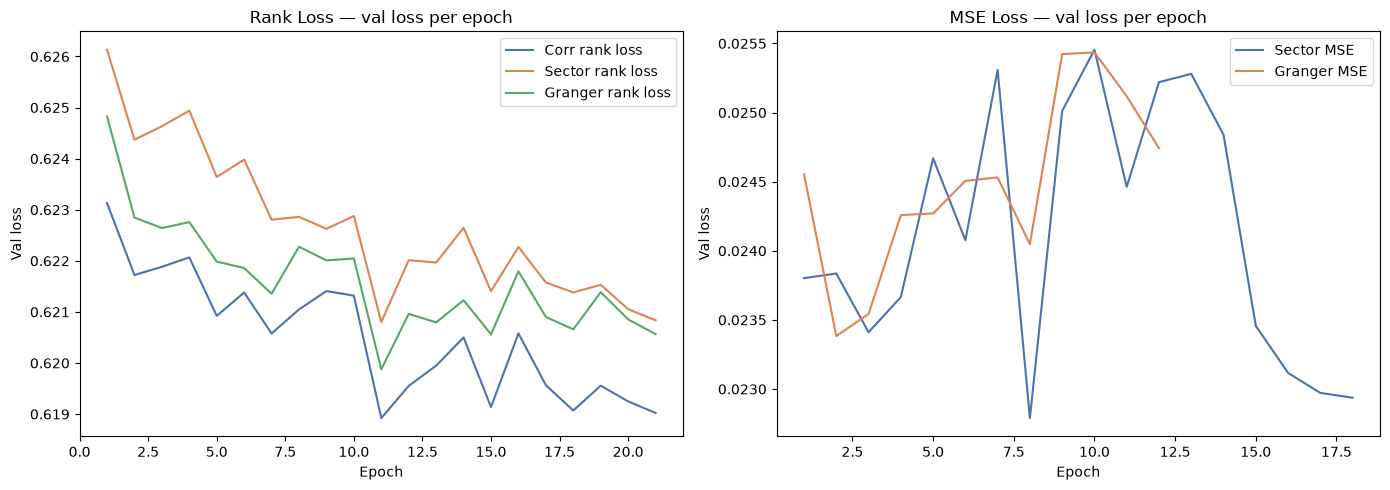

In [38]:
import matplotlib.pyplot as plt

rl_curves = {
    'Corr rank loss':    json.load(open(results_dir / 'gnn_corr_rankloss_val_loss.json'))['val_loss'],
    'Sector rank loss':  json.load(open(results_dir / 'gnn_sector_rankloss_val_loss.json'))['val_loss'],
    'Granger rank loss': json.load(open(results_dir / 'gnn_granger_rankloss_val_loss.json'))['val_loss'],
}
mse_curves = {}
for label, filename in [
    (f'Corr MSE (θ={best_theta})', f'gnn_corr_th{int(best_theta*10):02d}_val_loss.json'),
    ('Sector MSE', 'gnn_sector_val_loss.json'),
    ('Granger MSE', 'gnn_granger_val_loss.json'),
]:
    loss_path = results_dir / filename
    if loss_path.is_file():
        with loss_path.open() as f:
            mse_curves[label] = json.load(f)['val_loss']
    else:
        print(f'Skipping {label} curve; {filename} is missing.')
colors = ['#4C72B0', '#DD8452', '#55A868']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, curves, title in [
    (axes[0], rl_curves,  'Rank Loss — val loss per epoch'),
    (axes[1], mse_curves, 'MSE Loss — val loss per epoch'),
]:
    if curves:
        for (label, values), color in zip(curves.items(), colors):
            ax.plot(range(1, len(values) + 1), values, label=label, color=color, linewidth=1.5)
        ax.legend()
    else:
        ax.text(0.5, 0.5, 'No MSE loss files found\nRun MSE training in 04_gnn_models.ipynb',
                ha='center', va='center', transform=ax.transAxes)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Val loss')
    ax.set_title(title)
plt.tight_layout()
plt.show()

## Ranking Evaluation Metrics

Computes Rank IC, ICIR, IC t-stat/p-value, top-25% hit rate, and pairwise accuracy
on the **test set** for all six GNN variants (three MSE-trained, three rank-loss-trained).

- **Rank IC**: Spearman correlation between predicted and actual RV, cross-sectionally each week.
- **ICIR**: IC / std(IC) — measures consistency of the signal, not just average level.
- **Top-25% Hit Rate**: fraction of actual top-quartile high-vol stocks correctly identified in the predicted top quartile. Random baseline = 0.25.
- **Pairwise Accuracy**: fraction of stock pairs correctly ordered by predicted RV. Random baseline = 0.50.

The key comparison is MSE loss vs rank loss for each graph type. Rank loss directly
optimizes pairwise accuracy, so it should improve that metric. Whether Rank IC and
hit rate also improve tells us if the ranking improvement generalizes.

In [39]:
from src.evaluate import compute_all_ranking_metrics, RankingEvalResult

# Test-period target (actual RV for week T+1, stored at row T)
test_weeks  = sorted(splits.loc[splits['split'] == 'test', 'week'])
target_test = target_df.reindex(test_weeks)

# Load MSE model test predictions (saved by 05_evaluate.ipynb or run_test_evaluation)
mse_pred_keys = {
    f'GNN-Corr (θ={best_theta}, MSE)': 'gnn_corr',
    'GNN-Sector (MSE)':                'gnn_sector',
    'GNN-Granger (MSE)':               'gnn_granger',
}
rl_pred_keys = {
    'GNN-Corr (rank loss)':    'gnn_corr_rankloss',
    'GNN-Sector (rank loss)':  'gnn_sector_rankloss',
    'GNN-Granger (rank loss)': 'gnn_granger_rankloss',
}

all_pred_keys = {**mse_pred_keys, **rl_pred_keys}
results: list[RankingEvalResult] = []

for label, key in all_pred_keys.items():
    path = results_dir / f'test_preds_{key}.parquet'
    if not path.exists():
        print(f'  Skipping {label} — {path.name} not found')
        continue
    preds_test = pd.read_parquet(path).reindex(target_test.index)
    r = compute_all_ranking_metrics(preds_test, target_test, model_name=label)
    results.append(r)
    print(f'  {label}: IC={r.mean_ic:.4f}  ICIR={r.icir:.3f}  hit={r.mean_hit_rate:.3f}  pair={r.mean_pairwise_acc:.3f}')

# Summary table
summary_rows = [
    {
        'Model':           r.model_name,
        'Mean IC':         round(r.mean_ic,         4),
        'ICIR':            round(r.icir,             3),
        'IC t-stat':       round(r.ic_tstat,         2),
        'IC p-value':      round(r.ic_pvalue,        4),
        '% IC > 0':        round(r.pct_positive_ic,  3),
        'Hit Rate (25%)':  round(r.mean_hit_rate,    3),
        'Pairwise Acc':    round(r.mean_pairwise_acc, 3),
    }
    for r in results
]
summary_df = pd.DataFrame(summary_rows).set_index('Model')
print()
print(summary_df.to_string())

  Skipping GNN-Corr (θ=0.3, MSE) — test_preds_gnn_corr.parquet not found
  Skipping GNN-Sector (MSE) — test_preds_gnn_sector.parquet not found
  Skipping GNN-Granger (MSE) — test_preds_gnn_granger.parquet not found
  GNN-Corr (rank loss): IC=0.4309  ICIR=3.973  hit=0.513  pair=0.486
  GNN-Sector (rank loss): IC=0.4192  ICIR=4.251  hit=0.509  pair=0.479
  GNN-Granger (rank loss): IC=0.4168  ICIR=4.344  hit=0.508  pair=0.461

                         Mean IC   ICIR  IC t-stat  IC p-value  % IC > 0  Hit Rate (25%)  Pairwise Acc
Model                                                                                                 
GNN-Corr (rank loss)      0.4309  3.973      40.32         0.0       1.0           0.513         0.486
GNN-Sector (rank loss)    0.4192  4.251      43.15         0.0       1.0           0.509         0.479
GNN-Granger (rank loss)   0.4168  4.344      44.09         0.0       1.0           0.508         0.461


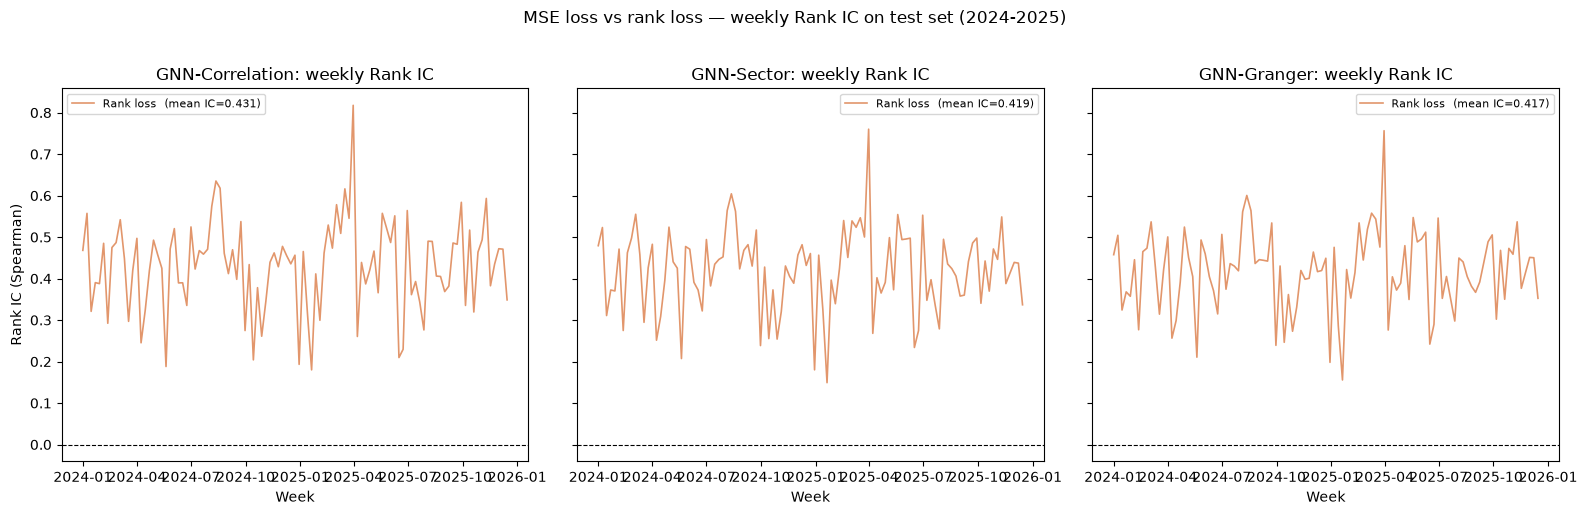

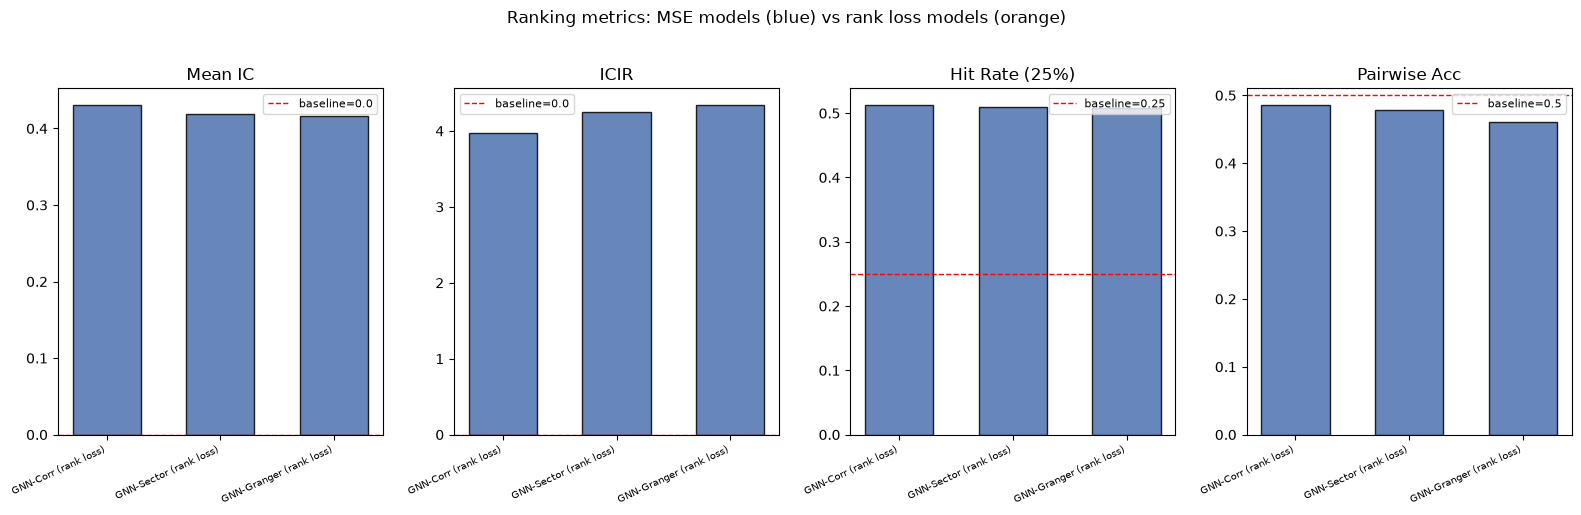

In [40]:
import matplotlib.pyplot as plt

# Pair up MSE vs rank loss results by graph type for direct comparison
graph_types = [
    ('Correlation', f'GNN-Corr (θ={best_theta}, MSE)', 'GNN-Corr (rank loss)'),
    ('Sector',      'GNN-Sector (MSE)',                 'GNN-Sector (rank loss)'),
    ('Granger',     'GNN-Granger (MSE)',                'GNN-Granger (rank loss)'),
]
results_by_name = {r.model_name: r for r in results}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, (graph, mse_label, rl_label) in zip(axes, graph_types):
    mse_r = results_by_name.get(mse_label)
    rl_r  = results_by_name.get(rl_label)

    if mse_r is not None:
        ax.plot(mse_r.ic_series.index, mse_r.ic_series.values,
                color='#4C72B0', linewidth=1.2, alpha=0.85,
                label=f'MSE  (mean IC={mse_r.mean_ic:.3f})')
    if rl_r is not None:
        ax.plot(rl_r.ic_series.index, rl_r.ic_series.values,
                color='#DD8452', linewidth=1.2, alpha=0.85,
                label=f'Rank loss  (mean IC={rl_r.mean_ic:.3f})')

    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(f'GNN-{graph}: weekly Rank IC')
    ax.set_xlabel('Week')
    ax.legend(fontsize=8)

axes[0].set_ylabel('Rank IC (Spearman)')
plt.suptitle('MSE loss vs rank loss — weekly Rank IC on test set (2024-2025)', y=1.02)
plt.tight_layout()
plt.show()

# Bar chart: key scalar metrics side by side for all 6 models
metric_cols  = ['Mean IC', 'ICIR', 'Hit Rate (25%)', 'Pairwise Acc']
baselines    = [0.0, 0.0, config.TOP_K_HIT_RATE_Q, 0.5]
n_metrics    = len(metric_cols)
n_models     = len(summary_df)
x            = np.arange(n_models)
width        = 0.18
bar_colors   = ['#4C72B0', '#4C72B0', '#4C72B0', '#DD8452', '#DD8452', '#DD8452']

fig, axes = plt.subplots(1, n_metrics, figsize=(16, 5))
for ax, col, baseline in zip(axes, metric_cols, baselines):
    vals = summary_df[col].values
    bars = ax.bar(x, vals, color=bar_colors, edgecolor='k', alpha=0.85, width=0.6)
    ax.axhline(baseline, color='red', linestyle='--', linewidth=1.0, label=f'baseline={baseline}')
    ax.set_xticks(x)
    ax.set_xticklabels(summary_df.index, rotation=25, ha='right', fontsize=7)
    ax.set_title(col)
    ax.legend(fontsize=8)

plt.suptitle('Ranking metrics: MSE models (blue) vs rank loss models (orange)', y=1.02)
plt.tight_layout()
plt.show()